# Intro to Data Visualization (Fall 2026) - Assignment 3

**EU Citizens on AI and the Gender Bias of Generative AI**

Group members: Amar Preet Singh, Samridh Barthaval, Prakash Periyasamy

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
import seaborn as sns
from pywaffle import Waffle

## Question 1 - Diverging Bar Plot - How important is it to shape AI development?

Each EU country is one horizontal bar. The survey counts are turned into percentages inside each
country, so every bar adds up to 100%. The "Don't know" share sits in the middle and is centred on
the zero line. The two "important" answers grow to the right and the two "not important" answers
grow to the left. This lets us compare agreement and disagreement around the same baseline.

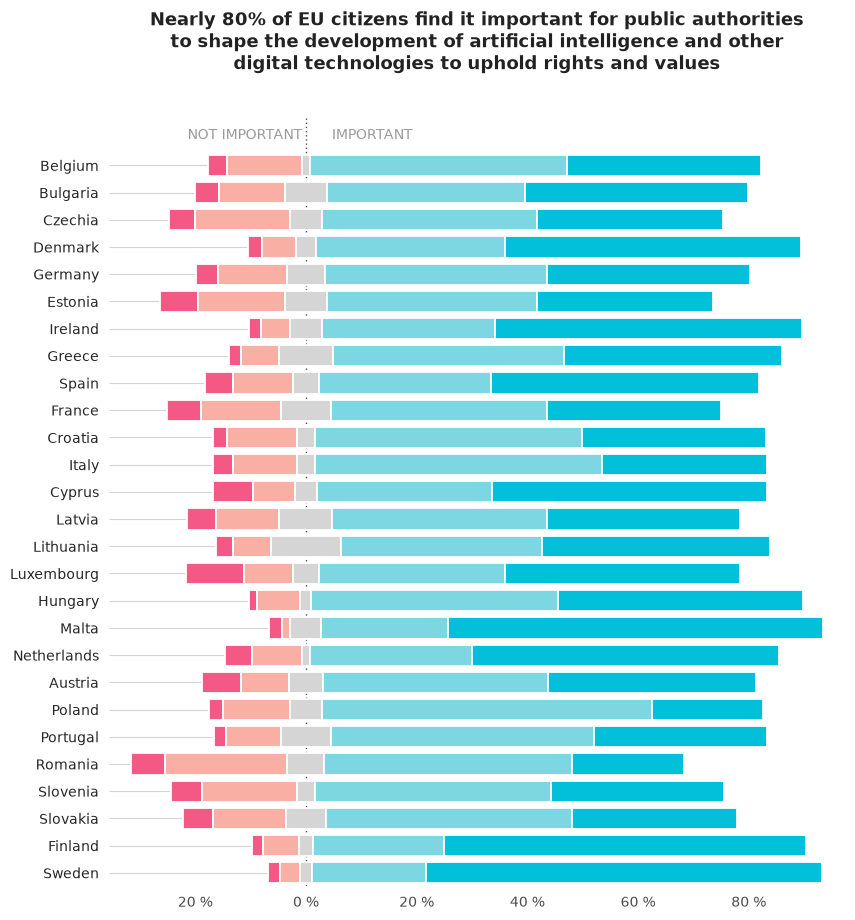

In [2]:
country_code_to_name = {
    "BE": "Belgium", "BG": "Bulgaria", "CZ": "Czechia", "DK": "Denmark",
    "DE": "Germany", "EE": "Estonia", "IE": "Ireland", "EL": "Greece",
    "ES": "Spain", "FR": "France", "HR": "Croatia", "IT": "Italy",
    "CY": "Cyprus", "LV": "Latvia", "LT": "Lithuania", "LU": "Luxembourg",
    "HU": "Hungary", "MT": "Malta", "NL": "Netherlands", "AT": "Austria",
    "PL": "Poland", "PT": "Portugal", "RO": "Romania", "SI": "Slovenia",
    "SK": "Slovakia", "FI": "Finland", "SE": "Sweden",
}
member_state_codes_top_to_bottom = list(country_code_to_name.keys())

survey_counts = pd.read_csv("eu-ai.csv", index_col=0)
survey_counts.index.name = "response"

total_people_per_country = survey_counts.sum(axis=0)
survey_percentages = survey_counts / total_people_per_country * 100

very_important_share       = survey_percentages.loc["Very important", member_state_codes_top_to_bottom].values
fairly_important_share     = survey_percentages.loc["Fairly important", member_state_codes_top_to_bottom].values
not_very_important_share   = survey_percentages.loc["Not very important", member_state_codes_top_to_bottom].values
not_at_all_important_share = survey_percentages.loc["Not at all important", member_state_codes_top_to_bottom].values
dont_know_share            = survey_percentages.loc["Don't know", member_state_codes_top_to_bottom].values

half_of_dont_know_share = dont_know_share / 2.0
not_at_all_left_edge = -(half_of_dont_know_share + not_very_important_share + not_at_all_important_share)
not_very_left_edge   = -(half_of_dont_know_share + not_very_important_share)
dont_know_left_edge  = -half_of_dont_know_share
fairly_left_edge     = half_of_dont_know_share
very_left_edge       = half_of_dont_know_share + fairly_important_share

colour_very_important       = "#02C0D9"
colour_fairly_important     = "#7DD7E3"
colour_dont_know            = "#D5D5D5"
colour_not_very_important   = "#F9AFA4"
colour_not_at_all_important = "#F35984"
colour_horizontal_guide     = "#D5D5D5"

number_of_countries = len(member_state_codes_top_to_bottom)
row_positions = range(number_of_countries)
bar_height = 0.78

sns.set_style("white")
figure, axes = plt.subplots(figsize=(9.5, 10.0))

largest_not_important_reach = float((half_of_dont_know_share + not_very_important_share + not_at_all_important_share).max())
largest_important_reach     = float((half_of_dont_know_share + fairly_important_share + very_important_share).max())
left_axis_limit  = -(largest_not_important_reach + 4)
right_axis_limit = largest_important_reach + 4

axes.hlines(y=list(row_positions), xmin=left_axis_limit, xmax=0,
            color=colour_horizontal_guide, linewidth=0.8, zorder=0.5)
axes.axvline(0, color="#4d4d4d", linewidth=1.0, linestyle=(0, (1, 2)), zorder=0.6)

white_gap_between_segments = dict(edgecolor="white", linewidth=1.3, zorder=2)
axes.barh(row_positions, not_at_all_important_share, left=not_at_all_left_edge, height=bar_height,
          color=colour_not_at_all_important, **white_gap_between_segments)
axes.barh(row_positions, not_very_important_share, left=not_very_left_edge, height=bar_height,
          color=colour_not_very_important, **white_gap_between_segments)
axes.barh(row_positions, dont_know_share, left=dont_know_left_edge, height=bar_height,
          color=colour_dont_know, **white_gap_between_segments)
axes.barh(row_positions, fairly_important_share, left=fairly_left_edge, height=bar_height,
          color=colour_fairly_important, **white_gap_between_segments)
axes.barh(row_positions, very_important_share, left=very_left_edge, height=bar_height,
          color=colour_very_important, **white_gap_between_segments)

axes.set_xlim(left_axis_limit, right_axis_limit)
axes.set_ylim(number_of_countries - 0.5, -1.8)

axes.set_yticks(list(row_positions))
axes.set_yticklabels([country_code_to_name[code] for code in member_state_codes_top_to_bottom], fontsize=10)
axes.tick_params(left=False)

axes.set_xticks([-20, 0, 20, 40, 60, 80])
axes.xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda value, position: f"{abs(int(round(value)))} %"))
axes.tick_params(axis="x", labelsize=10, colors="#4d4d4d")

axes.text(-11, -1.1, "NOT IMPORTANT", ha="center", va="center", fontsize=10, color="#9a9a9a")
axes.text(12, -1.1, "IMPORTANT", ha="center", va="center", fontsize=10, color="#9a9a9a")

figure_title = ("Nearly 80% of EU citizens find it important for public authorities\n"
                "to shape the development of artificial intelligence and other\n"
                "digital technologies to uphold rights and values")
axes.set_title(figure_title, fontsize=13, fontweight="bold", pad=34, color="#222222")

sns.despine(ax=axes, left=True, top=True, right=True, bottom=True)
plt.show()

**Question 1 written response:** Describe how public opinion on shaping AI development varies across EU countries, and explain, in your vision, why a diverging bar plot communicates this better than a standard (single-direction) stacked bar chart.

Public opinion is mostly positive in every EU country. Across the whole EU about 80% of people say it is important for public authorities to shape AI so that it protects our rights and values, so the long right (blue) side is the biggest part in almost every bar.

But the strength of this opinion is not the same everywhere. Countries like Malta, Ireland, Denmark, Sweden, Finland and Hungary have very long "important" sides (around 90%), and Sweden and Finland in particular have a large dark-blue "Very important" part. Countries like Romania, Estonia, Czechia and France have longer "not important" sides (pink), so more people there feel it is not important. Some countries, such as Lithuania, Latvia and Greece, have a wider grey "Don't know" part, which means more people there are unsure.

A diverging bar plot shows this better than a normal single-direction stacked bar because all the bars share the same zero line in the middle. The "important" answers grow to the right and the "not important" answers grow to the left, so the two opposite feelings are easy to compare for every country, and the length on each side can be read directly. We can quickly see how big the "against" side is and compare it between countries. In a normal stacked bar that goes only from 0% to 100%, the "not important" part starts at a different place in every bar, so it has no common baseline and the size of the minority who disagree is hard to compare. Centring "Don't know" on zero also keeps the neutral answer out of the two camps.

## Question 2 - Waffle Chart - Gender breakdown of AI-generated people per occupation

There is one waffle per occupation. Each waffle is a grid of 20 rows by 15 columns, so it holds 300
equal squares and each square is one generated image. The squares are filled from the bottom up:
men first (dark green), then women (mint), then ambiguous (grey) at the top. The occupations are
split into high-paying jobs (top row) and low-paying jobs (bottom row).

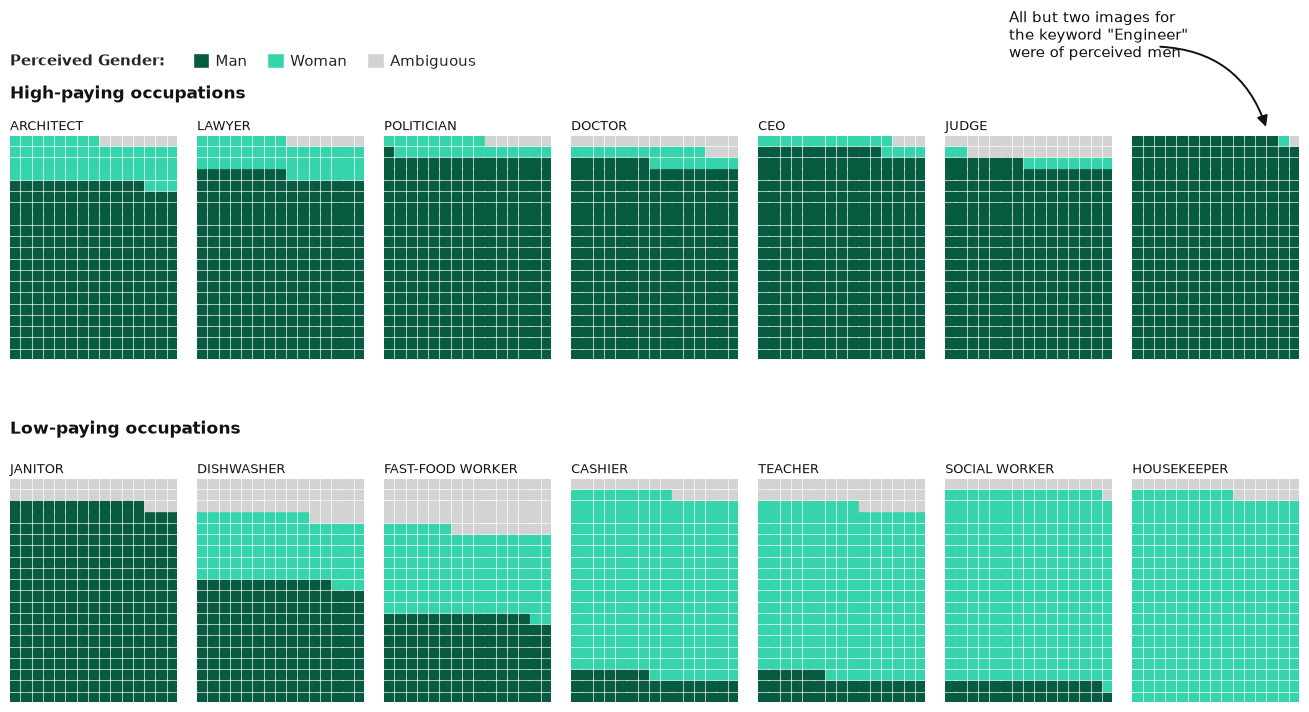

In [3]:
gender_counts = pd.read_csv("gen-ai.csv")

colour_man = "#065B41"
colour_woman = "#36D4AC"
colour_ambiguous = "#D3D3D3"
gender_colours = [colour_man, colour_woman, colour_ambiguous]

high_paying_occupations = ["architect", "lawyer", "politician", "doctor", "ceo", "judge", "engineer"]
low_paying_occupations = ["janitor", "dishwasher", "fast-food worker", "cashier", "teacher", "social worker", "housekeeper"]

def man_woman_ambiguous_values(occupation_name):
    occupation_row = gender_counts.loc[gender_counts["occupation"] == occupation_name].iloc[0]
    return [int(occupation_row["man"]), int(occupation_row["woman"]), int(occupation_row["ambiguous"])]

figure = plt.figure(figsize=(13.5, 7.4))
waffle_grid = figure.add_gridspec(nrows=2, ncols=7,
                                  left=0.035, right=0.99, top=0.82, bottom=0.03,
                                  wspace=0.12, hspace=0.42)

occupation_axes = {}

def draw_one_waffle_row(occupation_names, grid_row_index):
    for column_index, occupation_name in enumerate(occupation_names):
        axes = figure.add_subplot(waffle_grid[grid_row_index, column_index])
        Waffle.make_waffle(
            ax=axes, rows=20, columns=15,
            values=man_woman_ambiguous_values(occupation_name),
            colors=gender_colours, vertical=True, starting_location="SW",
            interval_ratio_x=0.2, interval_ratio_y=0.2, block_aspect_ratio=1,
        )
        axes.set_aspect("equal")
        if occupation_name != "engineer":
            axes.set_title(occupation_name.upper(), loc="left", fontsize=9.5, color="#111111", pad=4)
        occupation_axes[occupation_name] = axes

draw_one_waffle_row(high_paying_occupations, 0)
draw_one_waffle_row(low_paying_occupations, 1)

figure.text(0.035, 0.858, "High-paying occupations", fontsize=12.5, fontweight="bold", color="#111111")
figure.text(0.035, 0.405, "Low-paying occupations", fontsize=12.5, fontweight="bold", color="#111111")

figure.text(0.035, 0.908, "Perceived Gender:", fontsize=11, fontweight="bold", va="center")
legend_handles = [
    mpatches.Patch(facecolor=colour_man, label="Man"),
    mpatches.Patch(facecolor=colour_woman, label="Woman"),
    mpatches.Patch(facecolor=colour_ambiguous, label="Ambiguous"),
]
figure.legend(handles=legend_handles, loc="center left", bbox_to_anchor=(0.16, 0.908),
              ncol=3, frameon=False, fontsize=11, handlelength=1.1, handleheight=1.1,
              columnspacing=1.3, handletextpad=0.4)

engineer_annotation_text = ('All but two images for\n'
                            'the keyword "Engineer"\n'
                            'were of perceived men')
figure.text(0.775, 0.978, engineer_annotation_text, fontsize=10.5, va="top", ha="left", color="#111111")
engineer_pointer = FancyArrowPatch(
    (0.885, 0.928), (0.966, 0.816), transform=figure.transFigure,
    connectionstyle="arc3,rad=-0.35", arrowstyle="-|>", mutation_scale=16,
    linewidth=1.4, color="#111111")
figure.add_artist(engineer_pointer)

plt.show()

**Question 2 written response:** Describe the difference in the gender breakdown of AI-generated people between high-paying and low-paying occupations, and explain why a waffle chart communicates this better than a pie chart per occupation.

High-paying occupations are shown almost entirely as men. For architect, lawyer, politician, doctor, ceo, judge and engineer the waffles are mostly dark green (man). Engineer is the strongest example: 298 of the 300 images are men.

Low-paying occupations are very different. Janitor is still mostly men, and dishwasher and fast-food worker are mixed, but cashier, teacher, social worker and housekeeper are mostly women (mint green), and housekeeper has no men at all. So the model shows high-paying, high-status jobs as men and several low-paying or care jobs as women. This repeats and makes stronger the common gender stereotypes about these jobs. The "ambiguous" part stays small for most occupations. It is largest for fast-food worker, at 69 of 300 (about 23%).

A waffle chart shows this better than one pie chart per occupation because every waffle uses the same grid of 300 equal squares, and each square is one image. The squares make each share easy to read as a simple count, and because all 14 waffles have the same shape and size, we can compare them side by side very quickly. Pie charts are hard to compare across many small charts, because the human eye is not good at judging angles and areas, so small differences (for example architect at about 79% men against lawyer at about 83%) are difficult to see, and reading 14 separate pies to find the pattern is slow. The grid of waffles lines up neatly and makes the overall difference between high-paying and low-paying jobs clear at a glance.

## Attribution

This assignment was completed by Group 9: Amar Preet Singh, Samridh Barthaval, and Prakash Periyasamy.

The visualisations were built using only pandas, Matplotlib, Seaborn and PyWaffle. We used pandas to load and reshape the two data sets, Matplotlib and Seaborn for the diverging bar plot, and Matplotlib with PyWaffle for the waffle charts. We referred to the official Matplotlib, Seaborn and PyWaffle documentation for the plotting syntax.

The data sets and the original chart ideas come from the sources named in the assignment brief:
- "Humans are Biased. Generative AI is Even Worse," Leonardo Nicoletti and Dina Bass, Bloomberg.
- "EU Data Stories," Nadieh Bremer, visualcinnamon.com.
- "A Promising Horizon: How the 2025-2027 Horizon Europe strategic plan will shape Europe's tomorrow," European Data.
- "Special Eurobarometer SP551: The Digital Decade," European Data.

We also used an AI assistant to help debug our code and to compare our figures against the reference images in the assignment, which helped us match the colours, layout and text labels.